# TALLER: INTEGRACIÓN NUMÉRICA Y OPTIMIZACIÓN
## Generación de energía solar fotovoltaica en Colombia

**Curso:** Métodos Numéricos y Optimización

**Integrantes:**
1. Neyder Fabían Peña González 2252004
2. Julio Cesar Sierra Jiménez  2251502
3. Kevin Adrian Romero Lozada  2251503

En este notebook se resuelven cinco problemas sobre generación solar fotovoltaica en Colombia con datos reales de NASA POWER para cinco ciudades: Riohacha, Valledupar, Medellín, Bogotá y Leticia.

Panel de referencia: $P_{pico}$ = 400 W, $V_{oc}$ = 49.5 V, $I_{sc}$ = 10.37 A, $\gamma$ = -0.0035 1/°C, NOCT = 43 °C.

In [115]:
# Instala PuLP 3. La versión 4 cambió la forma de crear variables y da el error de "lowBound".
# Si ya habías ejecutado el notebook, reinicia la sesión (Entorno de ejecución > Reiniciar sesión).
!pip install -q "pulp<4"

In [116]:
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import pulp
from scipy.special import lambertw          # solo para el valor verdadero de P2-d
from scipy.interpolate import CubicSpline   # solo como referencia en P3-g
from scipy.integrate import quad            # solo como referencia en P3-a

# Aviso si quedó cargada la versión 4 de PuLP
if int(pulp.__version__.split('.')[0]) >= 4:
    raise RuntimeError('Reinicia la sesión y ejecuta todo de nuevo (PuLP 4 no sirve aquí)')

np.set_printoptions(precision=6, suppress=True)
pd.options.display.float_format = '{:.6g}'.format
np.seterr(all='ignore')   # evita avisos cuando Newton diverge (P2-f)


# Ciudades: (latitud, longitud)
CIUDADES = {'Riohacha': (11.54, -72.91), 'Valledupar': (10.46, -73.25),
            'Medellin': (6.25, -75.56), 'Bogota': (4.71, -74.07),
            'Leticia': (-4.21, -69.94)}
NOMBRES = list(CIUDADES)
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
         'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']


# Panel de referencia
P_PICO = 400.0      # W
V_OC = 49.5         # V
I_SC = 10.37        # A
GAMMA = -0.0035     # 1/°C
NOCT = 43.0         # °C
K_NOCT = (NOCT - 20) / 800
A_TH = 3.0          # V

In [117]:
URL = 'https://power.larc.nasa.gov/api/temporal/hourly/point'

# Esta función descarga un año de datos horarios de una ciudad
def descargar(lat, lon, anio=2023):
    params = {'parameters': 'ALLSKY_SFC_SW_DWN,T2M', 'community': 'RE',
              'longitude': lon, 'latitude': lat,
              'start': f'{anio}0101', 'end': f'{anio}1231',
              'format': 'JSON', 'time-standard': 'LST'}
    r = requests.get(URL, params=params, timeout=120)
    datos = r.json()['properties']['parameter']
    df = pd.DataFrame(datos).rename(columns={'ALLSKY_SFC_SW_DWN': 'GHI_Wm2',
                                              'T2M': 'T_amb_C'})
    df.index = pd.to_datetime(df.index, format='%Y%m%d%H')
    return df

In [118]:
from google.colab import files
import zipfile

print("Por favor, subí tu archivo datos_csv.zip:")
files.upload()

if os.path.exists('datos_csv.zip'):
    with zipfile.ZipFile('datos_csv.zip', 'r') as z:
        z.extractall('.')
    print("Archivos descomprimidos con éxito.")
else:
    print("No subiste el .zip, buscaremos los archivos .csv directos.")

Por favor, subí tu archivo datos_csv.zip:


Saving datos_csv.zip to datos_csv.zip
Archivos descomprimidos con éxito.


In [119]:
# Si el CSV de la ciudad existe se lee; si no, se descarga y se guarda
crudos = {}
for c in NOMBRES:
    archivo = f'data_{c}.csv'
    if os.path.exists(archivo):
        crudos[c] = pd.read_csv(archivo, index_col=0, parse_dates=True)
    else:
        lat, lon = CIUDADES[c]
        crudos[c] = descargar(lat, lon)
        crudos[c].to_csv(archivo)

print({c: crudos[c].shape for c in NOMBRES})

{'Riohacha': (8760, 2), 'Valledupar': (8760, 2), 'Medellin': (8760, 2), 'Bogota': (8760, 2), 'Leticia': (8760, 2)}


# PROBLEMA 1. Datos de irradiancia solar

Se usan los datos horarios de 2023 de NASA POWER: irradiancia global horizontal (GHI, W/m²) y temperatura ambiente (T2M, °C). El valor -999 indica dato faltante.

**(a)** calidad de los datos, **(b)** irradiación diaria promedio por mes, **(c)** gráficas, **(d)** análisis.

## a) Calidad de los datos

Se reemplaza -999 por NaN. Los huecos cortos (≤ 3 h) se interpolan linealmente y lo que quede se imputa con el promedio del mismo mes y la misma hora. Los GHI negativos (ruido nocturno) se llevan a 0.

In [120]:
# Esta función rellena los huecos de una serie
def rellenar(serie):
    serie = serie.interpolate(limit=3, limit_area='inside')    # huecos de hasta 3 h: línea recta
    promedio = serie.groupby([serie.index.month, serie.index.hour]).transform('mean')
    return serie.fillna(promedio)                              # el resto: promedio del mismo mes y hora


# Aquí se limpia cada ciudad y se arma la tabla de calidad
datos = {}
filas = []
for c in NOMBRES:
    df = crudos[c].copy()

    falt_ghi = (df['GHI_Wm2'] == -999).sum()
    falt_t = (df['T_amb_C'] == -999).sum()
    df = df.replace(-999, np.nan)
    negativos = (df['GHI_Wm2'] < 0).sum()

    df['GHI_Wm2'] = rellenar(df['GHI_Wm2'].clip(lower=0))
    df['T_amb_C'] = rellenar(df['T_amb_C'])
    datos[c] = df       # datos limpios: los usan los problemas 2 a 5

    filas.append({'Ciudad': c, 'Filas': len(df), 'Falt. GHI': falt_ghi,
                  'Falt. T': falt_t, 'GHI < 0': negativos,
                  'GHI máx. (W/m²)': df['GHI_Wm2'].max(),
                  'Tamb (°C)': df['T_amb_C'].mean()})

tabla_1a = pd.DataFrame(filas).set_index('Ciudad')
print('Valores vacíos que quedan tras la limpieza:', sum(d.isna().sum().sum() for d in datos.values()))
tabla_1a

Valores vacíos que quedan tras la limpieza: 0


,Filas,Falt. GHI,Falt. T,GHI < 0,GHI máx. (W/m²),Tamb (°C)
Ciudad,,,,,,
Riohacha,8760,0,0,0,1020.4,27.8541
Valledupar,8760,0,0,0,1030.6,23.2911
Medellin,8760,0,0,0,1026.15,16.8798
Bogota,8760,0,0,0,1009.62,18.8705
Leticia,8760,0,0,0,994.33,26.2947


**¿Por qué es razonable?**
- La irradiancia tiene un ciclo diario y estacional muy marcado: interpolar huecos cortos respeta la continuidad.
- El promedio mes-hora conserva el ciclo diario.
- Eliminar filas rompería el paso regular de 1 h que necesitan el trapecio y Simpson del Problema 3.

## b) Irradiación diaria promedio por mes (kWh/m²/día)

In [121]:
# Aquí se calcula la irradiación diaria promedio de cada mes
mensual = pd.DataFrame(index=MESES)
for c in NOMBRES:
    suma_mes = datos[c]['GHI_Wm2'].resample('MS').sum()           # Wh/m² de cada mes
    dias = suma_mes.index.days_in_month.values
    mensual[c] = suma_mes.values / 1000 / dias

promedio_anual = {c: datos[c]['GHI_Wm2'].sum() / 1000 / 365 for c in NOMBRES}

tabla_1b = pd.DataFrame({'Mes máx.': mensual.idxmax(), 'Valor máx.': mensual.max(),
                         'Mes mín.': mensual.idxmin(), 'Valor mín.': mensual.min(),
                         'Promedio anual': pd.Series(promedio_anual)})

display(mensual.T)
tabla_1b

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Riohacha,5.58574,5.93186,6.09999,6.15876,5.78837,6.0202,6.00738,6.1391,5.96502,5.30209,5.0632,4.9885
Valledupar,5.44322,6.30682,5.67985,5.40374,5.29601,5.15983,5.46063,5.50414,5.24115,4.71853,4.74294,5.05183
Medellin,4.80076,4.86738,4.17954,4.50185,5.11571,5.34225,5.55629,5.69319,5.74694,4.40132,4.74626,4.6741
Bogota,4.69693,5.15079,4.10996,4.24867,4.73645,4.79902,4.62606,5.02883,5.07741,4.89359,4.54569,4.44625
Leticia,4.37082,4.3281,4.42908,4.29327,4.15939,4.31213,4.81894,5.14738,5.38984,4.99115,4.60072,4.53051


,Mes máx.,Valor máx.,Mes mín.,Valor mín.,Promedio anual
Riohacha,Abr,6.15876,Dic,4.9885,5.7522
Valledupar,Feb,6.30682,Oct,4.71853,5.32822
Medellin,Sep,5.74694,Mar,4.17954,4.96837
Bogota,Feb,5.15079,Mar,4.10996,4.69322
Leticia,Sep,5.38984,May,4.15939,4.61625


## c) Visualización

(1) Barras agrupadas por mes. (2) Perfil horario promedio de GHI: enero y julio para Riohacha y Bogotá.

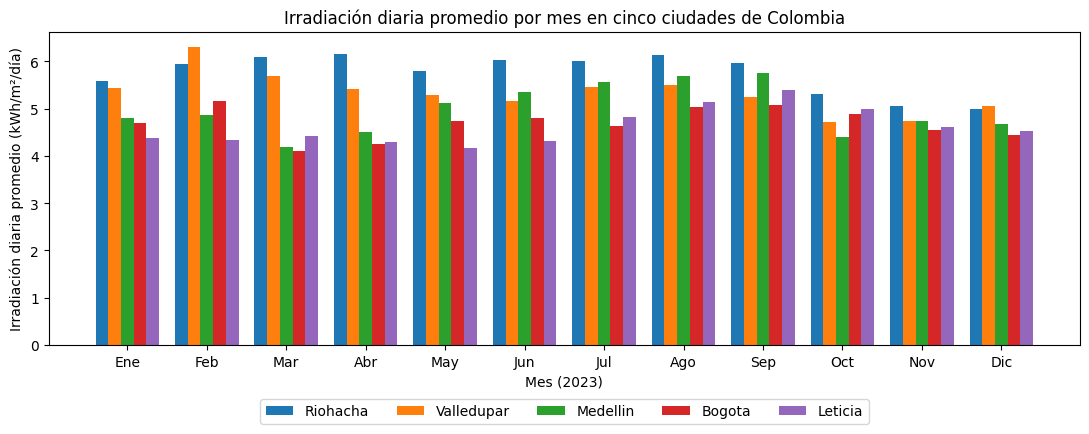

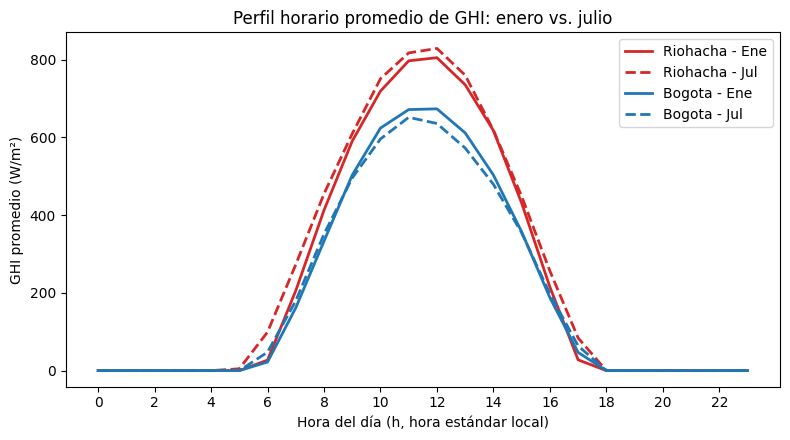

In [122]:
# Gráfica c.1: barras agrupadas
fig, ax = plt.subplots(figsize=(11, 4.5))
ancho = 0.16
x = np.arange(12)
for k, c in enumerate(NOMBRES):
    ax.bar(x + (k - 2) * ancho, mensual[c].values, width=ancho, label=c)
ax.set_xticks(x)
ax.set_xticklabels(MESES)
ax.set_xlabel('Mes (2023)')
ax.set_ylabel('Irradiación diaria promedio (kWh/m²/día)')
ax.set_title('Irradiación diaria promedio por mes en cinco ciudades de Colombia')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()


# Gráfica c.2: perfil horario promedio (ciudad, mes, color, estilo de línea)
curvas = [('Riohacha', 1, 'tab:red', '-'), ('Riohacha', 7, 'tab:red', '--'),
          ('Bogota', 1, 'tab:blue', '-'), ('Bogota', 7, 'tab:blue', '--')]

fig, ax = plt.subplots(figsize=(8, 4.5))
for ciudad, mes, color, estilo in curvas:
    ghi = datos[ciudad]['GHI_Wm2']
    ghi_mes = ghi[ghi.index.month == mes]
    perfil = ghi_mes.groupby(ghi_mes.index.hour).mean()
    ax.plot(perfil.index, perfil.values, color=color, ls=estilo, lw=2,
            label=f'{ciudad} - {MESES[mes - 1]}')
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hora del día (h, hora estándar local)')
ax.set_ylabel('GHI promedio (W/m²)')
ax.set_title('Perfil horario promedio de GHI: enero vs. julio')
ax.legend()
plt.tight_layout()
plt.show()

## d) Análisis

1. **Riohacha (~11° N).** Por geometría solar el Sol está más alto hacia abril y agosto. Si el máximo cae en meses secos (dic-mar), lo explica la nubosidad y el régimen de lluvias: en La Guajira la época seca domina.

2. **Variabilidad estacional.** Se mide con el coeficiente de variación $CV = \sigma/\mu$ de los promedios mensuales. Cerca del ecuador hay poca variación geométrica del Sol; la variación que se ve viene sobre todo de la nubosidad.

3. **Datos horarios vs. cada minuto.** Un promedio horario oculta los transitorios de las nubes. La ventaja de las reglas de alto orden (Simpson, Romberg) no se puede garantizar con datos reales.

In [123]:
# Coeficiente de variación de los 12 promedios mensuales de cada ciudad
cv = mensual.std(ddof=0) / mensual.mean() * 100

display(cv.sort_values(ascending=False).to_frame('CV (%)'))
print('Mes de mayor irradiación en Riohacha:', mensual['Riohacha'].idxmax(),
      f"({mensual['Riohacha'].max():.3f} kWh/m²/día)")
print('Ciudad con mayor variabilidad estacional:', cv.idxmax(), f'(CV = {cv.max():.2f} %)')

,CV (%)
Medellin,10.0197
Leticia,8.04477
Valledupar,7.60746
Riohacha,6.98754
Bogota,6.58493


Mes de mayor irradiación en Riohacha: Abr (6.159 kWh/m²/día)
Ciudad con mayor variabilidad estacional: Medellin (CV = 10.02 %)


### Conclusiones del Problema 1

Los datos quedaron completos: 8760 filas por ciudad (43 800 registros en total) y 0 valores vacíos después de la limpieza; no hubo faltantes de GHI/T2M ni GHI negativos. La GHI horaria máxima varió entre 994.33 W/m² (Leticia) y 1030.6 W/m² (Valledupar), y la temperatura ambiente media anual entre 16.88 °C (Medellín) y 27.85 °C (Riohacha).

La irradiación diaria promedio anual más alta fue Riohacha (5.752 kWh/m²/día) y la más baja Leticia (4.616 kWh/m²/día). En Riohacha el máximo mensual ocurrió en abril (6.159 kWh/m²/día) y el mínimo en diciembre (4.989 kWh/m²/día); el máximo mensual global fue Valledupar en febrero (6.307 kWh/m²/día) y el mínimo global Bogotá en marzo (4.110 kWh/m²/día).

El mayor coeficiente de variación mensual fue Medellín (CV = 10.02 %) y el menor Bogotá (CV = 6.58 %). Esto muestra que, aunque cerca del ecuador la geometría solar varía poco, la nubosidad introduce diferencias estacionales apreciables; por eso el análisis de irradiancia debe basarse en datos horarios reales y no solo en la posición solar.

# PROBLEMA 2. Modelo del panel y punto de máxima potencia

**Parte A:** modelo NOCT con coeficiente de temperatura y pérdida térmica anual.

**Parte B:** buscar $V_{mp}$ de la curva P-V con tres métodos (sección dorada, parabólica, Newton) y compararlos con el valor exacto (función W de Lambert).

## Parte A. Potencia en condiciones reales

a) Implementación y verificación del modelo NOCT:

$T_c = T_{amb} + K_{NOCT}\,G, \qquad K_{NOCT} = \dfrac{NOCT-20}{800}$

$P = P_{pico}\,\dfrac{G}{1000}\,\left[1 + \gamma (T_c - 25)\right]$

In [124]:
def T_celda(G, T_amb):
    """Temperatura de celda con el modelo NOCT.
    G [W/m²], T_amb [°C]. Retorna Tc [°C]. Funciona con números o arreglos."""
    G = np.asarray(G, dtype=float)
    T_amb = np.asarray(T_amb, dtype=float)
    return T_amb + K_NOCT * G


def P_panel(G, T_amb):
    """Potencia del panel con corrección lineal por temperatura.
    G [W/m²], T_amb [°C]. Retorna P [W]. Funciona con números o arreglos."""
    G = np.asarray(G, dtype=float)
    Tc = T_celda(G, T_amb)
    return P_PICO * (G / 1000) * (1 + GAMMA * (Tc - 25))


# Verificación con la tabla del enunciado
G_prueba = np.array([200, 500, 800, 1000, 1000])
Ta_prueba = np.array([25, 28, 28, 35, 14])
Tc_esperada = np.array([30.750, 42.375, 51.000, 63.750, 42.750])
Tc_calculada = T_celda(G_prueba, Ta_prueba)

verificacion = pd.DataFrame({'G (W/m²)': G_prueba, 'Tamb (°C)': Ta_prueba,
                             'Tc esperada (°C)': Tc_esperada,
                             'Tc calculada (°C)': Tc_calculada,
                             'Diferencia': np.abs(Tc_esperada - Tc_calculada)})
verificacion

,G (W/m²),Tamb (°C),Tc esperada (°C),Tc calculada (°C),Diferencia
0,200,25,30.75,30.75,0
1,500,28,42.375,42.375,0
2,800,28,51,51,0
3,1000,35,63.75,63.75,0
4,1000,14,42.75,42.75,0


b) Tabla de potencia para G ∈ {400, 600, 800, 1000} W/m² y Tamb ∈ {14, 22, 28, 35} °C.

In [125]:
Gs = [400, 600, 800, 1000]
Tas = [14, 22, 28, 35]

# Cada fila es un G y cada columna una Tamb
filas = []
for G in Gs:
    filas.append([float(P_panel(G, T)) for T in Tas])

tabla_P = pd.DataFrame(filas,
                       index=[f'G = {G} W/m²' for G in Gs],
                       columns=['14 °C (Bogotá)', '22 °C (Medellín)',
                                '28 °C (Riohacha)', '35 °C (Valledupar)'])
print('Potencia P [W]')
tabla_P

Potencia P [W]


,14 °C (Bogotá),22 °C (Medellín),28 °C (Riohacha),35 °C (Valledupar)
G = 400 W/m²,159.72,155.24,151.88,147.96
G = 600 W/m²,234.75,228.03,222.99,217.11
G = 800 W/m²,306.56,297.6,290.88,283.04
G = 1000 W/m²,375.15,363.95,355.55,345.75


c) Pérdida térmica anual:  $P_{pérdida} = \left(1 - \dfrac{\sum P_i}{\sum P_{pico} G_i/1000}\right)\cdot 100$

In [126]:
# Solo se usan las horas de sol (G > 0)
filas = []
for c in NOMBRES:
    d = datos[c]
    sol = d[d['GHI_Wm2'] > 0]
    G = sol['GHI_Wm2'].values
    Tamb = sol['T_amb_C'].values

    Tc = T_celda(G, Tamb)
    P_real = P_panel(G, Tamb)
    P_ideal = P_PICO * G / 1000        # potencia sin pérdida por temperatura

    filas.append({'Ciudad': c, 'Tc media (°C)': Tc.mean(), 'Tc máx. (°C)': Tc.max(),
                  'Pérdida anual (%)': (1 - P_real.sum() / P_ideal.sum()) * 100})

tabla_perdida = pd.DataFrame(filas).set_index('Ciudad')

if (tabla_perdida['Tc máx. (°C)'] >= 75).any():
    print('ATENCIÓN: Tc máx. por encima de 75 °C, revisar')
tabla_perdida

,Tc media (°C),Tc máx. (°C),Pérdida anual (%)
Ciudad,,,
Riohacha,42.2478,62.4341,8.10669
Valledupar,38.8201,60.1903,7.10027
Medellin,30.5313,53.0212,4.09827
Bogota,32.6398,54.2066,4.61075
Leticia,37.9103,59.2739,6.7055


**Análisis.** Bogotá es más fría, así que su pérdida porcentual es menor. Pero la energía generada depende sobre todo de la irradiación G: con menos irradiación, Bogotá no necesariamente genera más energía por panel.

## Parte B. Punto de máxima potencia

Modelo de un diodo: $I(V) = I_{sc} - I_0\,(e^{V/a} - 1)$, con $I_0 = \dfrac{I_{sc}}{e^{V_{oc}/a} - 1}$ y $P(V) = V\,I(V)$.

**d) Valor verdadero con la función W de Lambert.** Derivando: $P'(V) = I + V I' = 0$, que lleva a

$I_{sc} + I_0 = I_0\, e^{V/a}\,(1 + V/a)$

Con $u = 1 + V/a$ queda $u\,e^u = e\,(I_{sc}+I_0)/I_0$, y entonces

$V_{mp} = a\left[W\!\left(\dfrac{e\,(I_{sc}+I_0)}{I_0}\right) - 1\right]$

In [127]:
# P(V), su primera derivada y su segunda derivada (analíticas)
def P_V(V, Isc=I_SC):
    V = np.asarray(V, dtype=float)
    I0 = Isc / (np.exp(V_OC / A_TH) - 1)
    return V * (Isc - I0 * (np.exp(V / A_TH) - 1))

def dP_V(V, Isc=I_SC):
    V = np.asarray(V, dtype=float)
    I0 = Isc / (np.exp(V_OC / A_TH) - 1)
    return (Isc - I0 * (np.exp(V / A_TH) - 1)) - (V / A_TH) * I0 * np.exp(V / A_TH)

def d2P_V(V, Isc=I_SC):
    V = np.asarray(V, dtype=float)
    I0 = Isc / (np.exp(V_OC / A_TH) - 1)
    return -I0 * np.exp(V / A_TH) * (2 / A_TH + V / A_TH**2)


# Valor verdadero con Lambert W
I0_ref = I_SC / (np.exp(V_OC / A_TH) - 1)
Vmp_true = A_TH * (lambertw(np.e * (I_SC + I0_ref) / I0_ref).real - 1)
Pmp_true = float(P_V(Vmp_true))

print(f'I0      = {I0_ref:.6e} A')
print(f'Vmp     = {Vmp_true:.6f} V')
print(f'Pmp     = {Pmp_true:.6f} W')
print(f"P'(Vmp) = {float(dP_V(Vmp_true)):.3e}  (debe ser casi 0)")

I0      = 7.078151e-07 A
Vmp     = 41.415098 V
Pmp     = 400.465911 W
P'(Vmp) = 1.776e-15  (debe ser casi 0)


## e) Tres métodos de optimización unidimensional

Criterio de parada: $|\varepsilon_a| < 10^{-6}$ (error relativo aproximado).

1. **Sección dorada:** convergencia lineal (factor 0.618).
2. **Interpolación parabólica:** superlineal en teoría (orden ≈ 1.3).
3. **Newton:** cuadrática (necesita $P'$ y $P''$ analíticas).

In [128]:
TOL = 1e-6
R = (np.sqrt(5) - 1) / 2      # razón áurea


# Sección dorada (maximiza f en [xl, xu])
def seccion_dorada(f, xl, xu, tol=TOL):
    d = R * (xu - xl)
    x1, x2 = xl + d, xu - d
    f1, f2 = f(x1), f(x2)
    evaluaciones = 2
    historial = []

    for _ in range(200):
        if f1 > f2:                    # el máximo está a la derecha: se descarta [xl, x2]
            xl = x2
            x2, f2 = x1, f1
            x1 = xl + R * (xu - xl)
            f1 = f(x1)
        else:                          # el máximo está a la izquierda: se descarta [x1, xu]
            xu = x1
            x1, f1 = x2, f2
            x2 = xu - R * (xu - xl)
            f2 = f(x2)
        evaluaciones += 1

        x_opt = x1 if f1 > f2 else x2
        historial.append(x_opt)
        ea = (1 - R) * abs((xu - xl) / x_opt)
        if ea < tol:
            break

    return x_opt, historial, evaluaciones, xu - xl


# Interpolación parabólica (maximiza f con x0 < x1 < x2)
def parabolica(f, x0, x1, x2, tol=TOL):
    f0, f1, f2 = f(x0), f(x1), f(x2)
    evaluaciones = 3
    historial = []
    x_anterior = x1

    for _ in range(100):
        # x3 es el vértice de la parábola que pasa por los tres puntos
        num = f0 * (x1**2 - x2**2) + f1 * (x2**2 - x0**2) + f2 * (x0**2 - x1**2)
        den = 2 * f0 * (x1 - x2) + 2 * f1 * (x2 - x0) + 2 * f2 * (x0 - x1)
        x3 = num / den
        f3 = f(x3)
        evaluaciones += 1
        historial.append(x3)

        # se quedan los tres puntos que siguen encerrando el máximo
        if x3 > x1:
            if f3 > f1:
                x0, f0, x1, f1 = x1, f1, x3, f3
            else:
                x2, f2 = x3, f3
        else:
            if f3 > f1:
                x2, f2, x1, f1 = x1, f1, x3, f3
            else:
                x0, f0 = x3, f3

        ea = abs((x3 - x_anterior) / x3)
        x_anterior = x3
        if ea < tol:
            break

    return x3, historial, evaluaciones


# Newton sobre f'(x) = 0 (df y d2f son las derivadas analíticas)
def newton(df, d2f, x0, tol=TOL, max_iter=50):
    x = float(x0)
    historial = []

    for _ in range(max_iter):
        x_nuevo = x - df(x) / d2f(x)
        historial.append(float(x_nuevo))
        if not np.isfinite(x_nuevo):     # si se pierde, se detiene
            break
        ea = abs((x_nuevo - x) / x_nuevo)
        x = x_nuevo
        if ea < tol:
            break

    return x, historial

In [129]:
# Se corren los tres métodos
V_gs, h_gs, ev_gs, ancho_gs = seccion_dorada(P_V, 30, 48)
V_pa, h_pa, ev_pa = parabolica(P_V, 30, 40, 48)
V_nw, h_nw = newton(dP_V, d2P_V, 45)

# Error relativo verdadero en Vmp (%)
def error_true(V):
    return abs(V - Vmp_true) / abs(Vmp_true) * 100

tabla_metodos = pd.DataFrame([
    {'Método': 'Sección dorada', 'Iteraciones': len(h_gs), 'Eval. de P': ev_gs,
     "Eval. de P', P''": 0, 'Vmp (V)': V_gs, 'Pmp (W)': float(P_V(V_gs)),
     'εt en Vmp (%)': error_true(V_gs)},
    {'Método': 'Parabólica', 'Iteraciones': len(h_pa), 'Eval. de P': ev_pa,
     "Eval. de P', P''": 0, 'Vmp (V)': V_pa, 'Pmp (W)': float(P_V(V_pa)),
     'εt en Vmp (%)': error_true(V_pa)},
    {'Método': 'Newton', 'Iteraciones': len(h_nw), 'Eval. de P': 0,
     "Eval. de P', P''": f'{len(h_nw)} + {len(h_nw)}', 'Vmp (V)': V_nw,
     'Pmp (W)': float(P_V(V_nw)), 'εt en Vmp (%)': error_true(V_nw)},
]).set_index('Método')

print(f'Valor verdadero: Vmp = {Vmp_true:.6f} V, Pmp = {Pmp_true:.6f} W')
tabla_metodos

Valor verdadero: Vmp = 41.415098 V, Pmp = 400.465911 W


,Iteraciones,Eval. de P,"Eval. de P', P''",Vmp (V),Pmp (W),εt en Vmp (%)
Método,,,,,,
Sección dorada,25,27,0,41.4151,400.466,2.26132e-05
Parabólica,32,35,0,41.415,400.466,0.000203297
Newton,6,0,6 + 6,41.4151,400.466,1.71566e-14


## f) Convergencia

Gráfica de $\log_{10}|\varepsilon_t|$ contra la iteración, cota teórica de la sección dorada y prueba de Newton con un mal punto inicial.

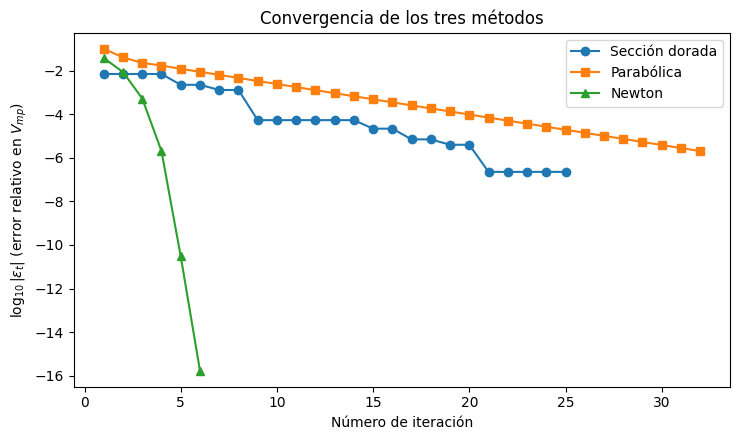

Ancho inicial = 18, ancho final = 1.073e-04
Cota teórica: n >= 25.0000  ->  n = 25
Iteraciones reales = 25

Newton con V0 = 30 V: [193.5354 190.5805 187.6263 184.6728 181.72   178.7679 175.8166 172.8661
 169.9164 166.9676 164.0196 161.0726]
P''(30) = -0.0624   P''(45) = -13.1119   P''(Vmp) = -3.6901
P'(30)  = 10.1985


In [130]:
# Log10 del error relativo en cada iteración
def log_error(historial):
    e = np.abs(np.array(historial) - Vmp_true) / abs(Vmp_true)
    return np.log10(np.maximum(e, 1e-16))      # el 1e-16 evita log(0)


fig, ax = plt.subplots(figsize=(7.5, 4.5))
for hist, nombre, marca in [(h_gs, 'Sección dorada', 'o'),
                            (h_pa, 'Parabólica', 's'),
                            (h_nw, 'Newton', '^')]:
    ax.plot(range(1, len(hist) + 1), log_error(hist), marker=marca, label=nombre)
ax.set_xlabel('Número de iteración')
ax.set_ylabel(r'$\log_{10}|\varepsilon_t|$ (error relativo en $V_{mp}$)')
ax.set_title('Convergencia de los tres métodos')
ax.legend()
plt.tight_layout()
plt.show()


# Cota teórica de la sección dorada: n >= ln(dx0/dx) / ln(1/R)
dx0 = 48 - 30
n_teorico = math.log(dx0 / ancho_gs) / math.log(1 / R)
print(f'Ancho inicial = {dx0}, ancho final = {ancho_gs:.3e}')
print(f'Cota teórica: n >= {n_teorico:.4f}  ->  n = {math.ceil(n_teorico - 1e-9)}')
print(f'Iteraciones reales = {len(h_gs)}')


# Newton empezando en V0 = 30 V
V_malo, h_malo = newton(dP_V, d2P_V, 30, max_iter=12)
print('\nNewton con V0 = 30 V:', np.array2string(np.array(h_malo), precision=4))
print(f"P''(30) = {float(d2P_V(30)):.4f}   P''(45) = {float(d2P_V(45)):.4f}   "
      f"P''(Vmp) = {float(d2P_V(Vmp_true)):.4f}")
print(f"P'(30)  = {float(dP_V(30)):.4f}")

**Análisis de convergencia**
- Sección dorada: convergencia lineal (factor R ≈ 0.618).
- Newton: convergencia cuadrática (las cifras correctas se duplican en cada iteración).
- Parabólica: superlineal en teoría; aquí la curva es muy asimétrica y eso puede volverla casi lineal.
- Newton con $V_0$ = 30 V: $|P''|$ es muy pequeña en esa zona, el paso se hace enorme y el método se aleja del máximo.
- Se prefiere la sección dorada cuando no hay derivadas o se quiere robustez. Newton solo con un buen punto inicial.

## g) Variación con la irradiancia

$I_{sc}(G) = 10.37\,G/1000$. Se usa Newton con $V_0$ = 45 V.

In [131]:
filas = []
for G in [200, 400, 600, 800, 1000]:
    Isc_G = I_SC * G / 1000

    # derivadas con el Isc de este G
    def dP_G(V):
        return dP_V(V, Isc_G)

    def d2P_G(V):
        return d2P_V(V, Isc_G)

    V, hist = newton(dP_G, d2P_G, 45)
    Pm = float(P_V(V, Isc_G))
    lineal = P_PICO * G / 1000          # aproximación lineal Ppico*G/1000

    filas.append({'G (W/m²)': G, 'Isc (A)': Isc_G, 'Vmp (V)': V, 'Pmp (W)': Pm,
                  'Ppico·G/1000 (W)': lineal,
                  'Dif. relativa (%)': (Pm - lineal) / Pm * 100,
                  'Iter. Newton': len(hist)})

tabla_G = pd.DataFrame(filas).set_index('G (W/m²)')
print('Variación de Vmp entre G=200 y G=1000:',
      f"{tabla_G['Vmp (V)'].max() - tabla_G['Vmp (V)'].min():.3e} V")
tabla_G

Variación de Vmp entre G=200 y G=1000: 0.000e+00 V


,Isc (A),Vmp (V),Pmp (W),Ppico·G/1000 (W),Dif. relativa (%),Iter. Newton
G (W/m²),,,,,,
200,2.074,41.4151,80.0932,80,0.116342,6
400,4.148,41.4151,160.186,160,0.116342,6
600,6.222,41.4151,240.28,240,0.116342,6
800,8.296,41.4151,320.373,320,0.116342,6
1000,10.37,41.4151,400.466,400,0.116342,6


**Análisis.** $V_{mp}$ no cambia con G en este modelo (porque $I_0 \propto I_{sc}$), y $P_{mp}$ es proporcional a G. La aproximación lineal $P \approx P_{pico}\,G/1000$ es muy buena. Limitación: en un panel real $V_{mp}$ baja un poco con la irradiancia.

### Conclusiones del Problema 2
1. Pérdida térmica anual de pocos por ciento, menor en la ciudad más fría.
2. $V_{mp}$ y $P_{mp}$ coinciden con Lambert con 6 decimales.
3. Newton es el más eficiente, pero exige un buen punto inicial.
4. $V_{mp}$ no depende de G, lo que justifica el modelo $P \propto G$ del Problema 3.

# PROBLEMA 3. Integración numérica de la energía

$E_{dia} = \int_0^{24} P(t)\,dt$

**Parte A:** día de cielo despejado con valor verdadero conocido (trapecio, Simpson 1/3, Romberg, Gauss-Legendre).

**Parte B:** datos reales (potencia cada hora) y energía anual por panel.

## Parte A. Día de cielo despejado

$G(t) = 1000\,\sin\!\left(\pi (t-6)/12\right)$ entre las 6:00 y las 18:00, con $T_{amb}$ = 28 °C. Como $T_c$ es lineal en G:

$P = 0.4\,G\,[1+\gamma(T_{amb}-25)] + 0.4\,\gamma\,k\,G^2$

Usando $\int_6^{18}\sin\theta\,dt = 24/\pi$ y $\int_6^{18}\sin^2\theta\,dt = 6$:

$E_{verd} = 0.4\,[1+\gamma(T_{amb}-25)]\cdot 1000\cdot\dfrac{24}{\pi} + 0.4\,\gamma\,k\cdot 1000^2\cdot 6$

In [132]:
T_AMB_A = 28.0

# Potencia del día despejado (t en horas; 0 fuera de 6-18 h)
def P_clara(t):
    t = np.asarray(t, dtype=float)
    G = np.where((t >= 6) & (t <= 18), 1000 * np.sin(np.pi * (t - 6) / 12), 0.0)
    return P_panel(G, T_AMB_A)


# Valor verdadero (fórmula de arriba)
E_verd = ((P_PICO / 1000) * (1 + GAMMA * (T_AMB_A - 25)) * 1000 * 24 / np.pi
          + (P_PICO / 1000) * GAMMA * K_NOCT * 1000**2 * 6)
print(f'E verdadera = {E_verd:.6f} Wh')

# Comprobación con SciPy (solo como referencia)
print(f'quad (referencia) = {quad(P_clara, 6, 18, epsabs=1e-12)[0]:.6f} Wh')

E verdadera = 2782.189271 Wh
quad (referencia) = 2782.189271 Wh


## b) Newton-Cotes

Trapecio y Simpson 1/3 compuestos entre 6 y 18 h, con n subintervalos.

In [133]:
# Trapecio compuesto con n subintervalos
def trapecio(f, a, b, n):
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)


# Simpson 1/3 compuesto (n debe ser par)
def simpson13(f, a, b, n):
    if n % 2 != 0:
        raise ValueError('Simpson 1/3 necesita n par')
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())


# Error relativo verdadero (%)
def err_pct(E):
    return abs(E_verd - E) / abs(E_verd) * 100


ns = [4, 6, 12, 24, 48]
filas = []
for n in ns:
    Et = trapecio(P_clara, 6, 18, n)
    Es = simpson13(P_clara, 6, 18, n)
    filas.append({'h (h)': 12 / n, 'n': n,
                  'E_trap (Wh)': Et, 'εt trapecio (%)': err_pct(Et),
                  'E_simp (Wh)': Es, 'εt Simpson (%)': err_pct(Es)})

tabla_3b = pd.DataFrame(filas).set_index('h (h)')
tabla_3b

,n,E_trap (Wh),εt trapecio (%),E_simp (Wh),εt Simpson (%)
h (h),,,,,
3,4,2625.14,5.64491,2789.08,0.247778
2,6,2712.79,2.49436,2783.49,0.0469058
1,12,2764.9,0.621446,2782.27,0.00285961
0.5,24,2777.87,0.155228,2782.19,0.000177631
0.25,48,2781.11,0.0387987,2782.19,1.1085e-05


## c) Orden de convergencia

En escala log-log la pendiente del error contra h debe ser 2 (trapecio) y 4 (Simpson).

Pendiente trapecio = 2.0037   (teórica 2)
Pendiente Simpson  = 4.0272   (teórica 4)


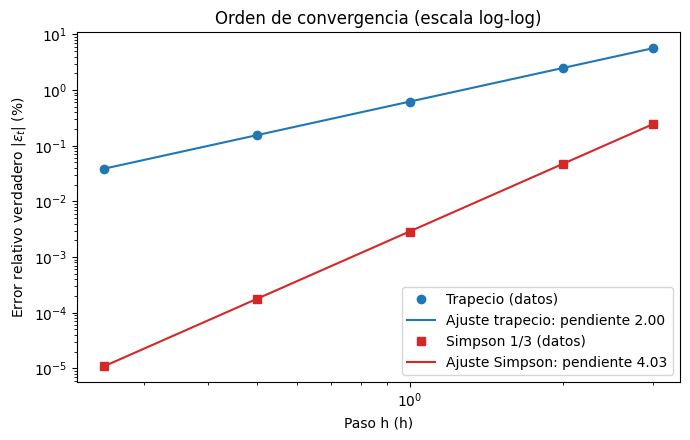

In [134]:
h_arr = np.array([12 / n for n in ns])
err_trap = np.array([err_pct(trapecio(P_clara, 6, 18, n)) for n in ns])
err_simp = np.array([err_pct(simpson13(P_clara, 6, 18, n)) for n in ns])

# Recta de mínimos cuadrados sobre log10(error) vs log10(h): la pendiente es el orden
m_trap, b_trap = np.polyfit(np.log10(h_arr), np.log10(err_trap), 1)
m_simp, b_simp = np.polyfit(np.log10(h_arr), np.log10(err_simp), 1)
print(f'Pendiente trapecio = {m_trap:.4f}   (teórica 2)')
print(f'Pendiente Simpson  = {m_simp:.4f}   (teórica 4)')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(h_arr, err_trap, 'o', color='tab:blue', label='Trapecio (datos)')
ax.loglog(h_arr, 10**(b_trap + m_trap * np.log10(h_arr)), '-', color='tab:blue',
          label=f'Ajuste trapecio: pendiente {m_trap:.2f}')
ax.loglog(h_arr, err_simp, 's', color='tab:red', label='Simpson 1/3 (datos)')
ax.loglog(h_arr, 10**(b_simp + m_simp * np.log10(h_arr)), '-', color='tab:red',
          label=f'Ajuste Simpson: pendiente {m_simp:.2f}')
ax.set_xlabel('Paso h (h)')
ax.set_ylabel(r'Error relativo verdadero $|\varepsilon_t|$ (%)')
ax.set_title('Orden de convergencia (escala log-log)')
ax.legend()
plt.tight_layout()
plt.show()

## d) Romberg

Tabla de Romberg con n = 4, 8, 16, 32 (el número de subintervalos se duplica). La segunda columna debe coincidir con Simpson 1/3.

$I_{j,k} = \dfrac{4^{k-1}\,I_{j+1,k-1} - I_{j,k-1}}{4^{k-1} - 1}$

In [135]:
# Tabla de Romberg: la columna 0 es el trapecio y cada columna siguiente mejora la anterior
def romberg(f, a, b, lista_n):
    m = len(lista_n)
    I = np.full((m, m), np.nan)

    for j in range(m):
        I[j, 0] = trapecio(f, a, b, lista_n[j])

    for k in range(1, m):
        for j in range(m - k):
            I[j, k] = (4**k * I[j + 1, k - 1] - I[j, k - 1]) / (4**k - 1)

    return I


ns_romb = [4, 8, 16, 32]
nombres_col = ['O(h²)', 'O(h⁴)', 'O(h⁶)', 'O(h⁸)']
nombres_fila = [f'n = {n}' for n in ns_romb]

I_romb = romberg(P_clara, 6, 18, ns_romb)
errores_romb = np.array([[err_pct(v) for v in fila] for fila in I_romb])

print('Tabla de Romberg [Wh]')
display(pd.DataFrame(I_romb, index=nombres_fila, columns=nombres_col))
print('Error relativo verdadero εt [%]')
display(pd.DataFrame(errores_romb, index=nombres_fila, columns=nombres_col))

# La segunda columna debe ser igual a Simpson 1/3 con n = 8, 16, 32
for j in range(3):
    print(f'n = {ns_romb[j + 1]}: Romberg {I_romb[j, 1]:.6f} | Simpson {simpson13(P_clara, 6, 18, ns_romb[j + 1]):.6f}')

Tabla de Romberg [Wh]


,O(h²),O(h⁴),O(h⁶),O(h⁸)
n = 4,2625.14,2782.6,2782.19,2782.19
n = 8,2743.23,2782.21,2782.19,NaN
n = 16,2772.47,2782.19,NaN,NaN
n = 32,2779.76,NaN,NaN,NaN


Error relativo verdadero εt [%]


,O(h²),O(h⁴),O(h⁶),O(h⁸)
n = 4,5.64491,0.0146267,1.34516e-05,3.24269e-09
n = 8,1.40026,0.000901559,2.0699e-07,NaN
n = 16,0.349388,5.61534e-05,NaN,NaN
n = 32,0.0873049,NaN,NaN,NaN


n = 8: Romberg 2782.596214 | Simpson 2782.596214
n = 16: Romberg 2782.214354 | Simpson 2782.214354
n = 32: Romberg 2782.190833 | Simpson 2782.190833


## e) Gauss-Legendre

Con $t = 12 + 6x$, $dt = 6\,dx$, $x \in [-1, 1]$:  $E \approx 6\sum_i w_i\,P(12 + 6x_i)$

In [136]:
# Gauss-Legendre de npts puntos en [a, b] (nodos y pesos de NumPy)
def gauss_legendre(f, a, b, npts):
    x, w = np.polynomial.legendre.leggauss(npts)
    t = (a + b) / 2 + (b - a) / 2 * x       # cambio de variable a [a, b]
    return (b - a) / 2 * np.sum(w * f(t))


filas = []
for npts in [2, 3, 4, 5]:
    Eg = gauss_legendre(P_clara, 6, 18, npts)
    filas.append({'Puntos': npts, 'E_Gauss (Wh)': Eg, 'εt (%)': err_pct(Eg)})

tabla_3e = pd.DataFrame(filas).set_index('Puntos')
tabla_3e

,E_Gauss (Wh),εt (%)
Puntos,,
2,2743.27,1.39895
3,2778.87,0.119434
4,2782.42,0.00841201
5,2782.18,0.000261387


## f) Eficiencia

Número de evaluaciones de P(t) necesarias para $|\varepsilon_t| < 0.01\,\%$.

In [137]:
TOL_PCT = 0.01

# Trapecio: se sube n de 1 en 1 hasta cumplir la tolerancia
n = 1
while err_pct(trapecio(P_clara, 6, 18, n)) >= TOL_PCT:
    n += 1
n_trap = n

# Simpson 1/3: n par
n = 2
while err_pct(simpson13(P_clara, 6, 18, n)) >= TOL_PCT:
    n += 2
n_simp = n

# Romberg: se agregan niveles (n = 1, 2, 4, 8, ...) hasta cumplir la tolerancia
niveles = 1
while True:
    lista_n = [2**k for k in range(niveles)]
    if err_pct(romberg(P_clara, 6, 18, lista_n)[0, niveles - 1]) < TOL_PCT:
        break
    niveles += 1
n_romb = lista_n[-1]

# Gauss-Legendre: se sube el número de puntos
npts = 1
while err_pct(gauss_legendre(P_clara, 6, 18, npts)) >= TOL_PCT:
    npts += 1

tabla_3f = pd.DataFrame({
    'Parámetro': [f'n = {n_trap}', f'n = {n_simp}',
                  f'{niveles} niveles (n máx. = {n_romb})', f'{npts} puntos'],
    'Evaluaciones de P(t)': [n_trap + 1, n_simp + 1, n_romb + 1, npts]},
    index=['Trapecio', 'Simpson 1/3', 'Romberg', 'Gauss-Legendre'])
tabla_3f

,Parámetro,Evaluaciones de P(t)
Trapecio,n = 95,96
Simpson 1/3,n = 10,11
Romberg,4 niveles (n máx. = 8),9
Gauss-Legendre,4 puntos,4


**Conclusión.** Gauss-Legendre necesita muchas menos evaluaciones que Newton-Cotes para la misma exactitud, Romberg queda en el medio y el trapecio es el más costoso. Si cada evaluación de P fuera costosa recomendaríamos Gauss-Legendre (o Romberg/Simpson si no se pueden elegir los nodos).

## Parte B. Datos reales

Con datos reales solo se conoce P cada hora (nodos fijos, h = 1 h), así que Gauss no se puede aplicar directamente.

In [138]:
# Potencia horaria de cada ciudad en W (un valor por hora, h = 1 h)
P_hora = {}
for c in NOMBRES:
    P_hora[c] = P_panel(datos[c]['GHI_Wm2'].values, datos[c]['T_amb_C'].values)


# Trapecio sobre datos cada h horas
def trapecio_datos(y, h=1.0):
    return h * (y[0] / 2 + y[1:-1].sum() + y[-1] / 2)

# Simpson 1/3 sobre datos (necesita un número PAR de subintervalos)
def simpson13_datos(y, h=1.0):
    return h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

# Simpson 3/8 sobre exactamente 3 subintervalos (4 puntos)
def simpson38_datos(y, h=1.0):
    return 3 * h / 8 * (y[0] + 3 * y[1] + 3 * y[2] + y[3])

# Si n es impar: Simpson 1/3 en casi todo y Simpson 3/8 en los últimos 3 subintervalos
def simpson_datos(y, h=1.0):
    n = len(y) - 1
    if n % 2 == 0:
        return simpson13_datos(y, h)
    return simpson13_datos(y[:-3], h) + simpson38_datos(y[-4:], h)

## g) Un día de enero (15 de enero)

Se usan 25 puntos (t = 0, 1, ..., 24 h) para tener 24 subintervalos, que es un número par.

In [139]:
t24 = np.arange(25.0)
inicio = 14 * 24            # el 15 de enero empieza en la hora 14*24 del año

filas = []
for c in NOMBRES:
    y = P_hora[c][inicio:inicio + 25]
    E_trap = trapecio_datos(y)
    E_simp = simpson13_datos(y)
    E_spline = float(CubicSpline(t24, y).integrate(0, 24))     # referencia
    filas.append({'Ciudad': c, 'Trapecio (Wh)': E_trap, 'Simpson 1/3 (Wh)': E_simp,
                  'Spline (Wh)': E_spline,
                  'Dif. trapecio vs spline (%)': (E_trap - E_spline) / E_spline * 100,
                  'Dif. Simpson vs spline (%)': (E_simp - E_spline) / E_spline * 100})

tabla_3g = pd.DataFrame(filas).set_index('Ciudad')
tabla_3g

,Trapecio (Wh),Simpson 1/3 (Wh),Spline (Wh),Dif. trapecio vs spline (%),Dif. Simpson vs spline (%)
Ciudad,,,,,
Riohacha,2057.53,2060.27,2057.53,-0.000157803,0.133205
Valledupar,1917.51,1913.87,1917.52,-0.00024514,-0.190043
Medellin,1933.93,1933.71,1933.94,-0.000385538,-0.0115762
Bogota,1856.49,1849.81,1856.49,-0.000294437,-0.360296
Leticia,1389.1,1387.29,1389.09,0.000730375,-0.130032


## h) Energía anual por panel

Hay 8760 valores, es decir 8759 subintervalos (impar). Se usa Simpson 1/3 en los primeros 8756 subintervalos y Simpson 3/8 en el último tramo de 3 subintervalos.

In [140]:
E_anual = {}          # kWh/panel/año (es la entrada del Problema 4)
E_anual_trap = {}
E_anual_suma = {}

for c in NOMBRES:
    y = P_hora[c]
    E_anual[c] = simpson_datos(y) / 1000
    E_anual_trap[c] = trapecio_datos(y) / 1000
    E_anual_suma[c] = y.sum() / 1000

tabla_3h = pd.DataFrame({'E_anual Simpson (kWh/panel/año)': E_anual,
                         'Trapecio': E_anual_trap,
                         'Suma horaria': E_anual_suma}).T

for c in NOMBRES:
    if not 400 <= E_anual[c] <= 800:
        print(f'ATENCIÓN: {c} tiene {E_anual[c]:.1f} kWh, fuera del rango 400-800')
tabla_3h

,Riohacha,Valledupar,Medellin,Bogota,Leticia
E_anual Simpson (kWh/panel/año),770.539,722.633,695.544,653.961,627.855
Trapecio,771.74,722.686,695.654,653.617,628.779
Suma horaria,771.74,722.686,695.654,653.617,628.779


## i) Análisis

1. **¿Se mantiene la ventaja de Simpson con datos reales?** Normalmente no: con h = 1 h y datos poco suaves los errores son parecidos. El spline no es un valor verdadero, es solo otra interpolación.

2. **Error de 0.5 % en E_anual** (200 paneles, 25 años, $0.08/kWh): ver la celda siguiente. Es pequeño frente a la inversión total y a otras incertidumbres, y no cambia la decisión de inversión.

In [141]:
promedio = np.mean(list(E_anual.values()))
kwh = 200 * promedio * 25 * 0.005
dolares = kwh * 0.08

print(f'Promedio de las 5 ciudades = {promedio:.2f} kWh/panel/año')
print(f'Un error de 0.5 % con 200 paneles durante 25 años: {kwh:,.0f} kWh = US$ {dolares:,.0f}')

dif = max(abs(E_anual[c] - E_anual_trap[c]) / E_anual[c] * 100 for c in NOMBRES)
print(f'Diferencia máxima entre Simpson y trapecio en E_anual: {dif:.4f} %')

Promedio de las 5 ciudades = 694.11 kWh/panel/año
Un error de 0.5 % con 200 paneles durante 25 años: 17,353 kWh = US$ 1,388
Diferencia máxima entre Simpson y trapecio en E_anual: 0.1558 %


### Conclusiones del Problema 3
1. En el día despejado: pendiente de Simpson ≈ 4 y del trapecio ≈ 2 (como dice la teoría).
2. Con datos reales solo se pueden usar fórmulas de Newton-Cotes (nodos fijos).
3. Los $E_{anual}$ están entre 400 y 800 kWh/panel/año y son la entrada del Problema 4.

# PROBLEMA 4. Optimización del portafolio de paneles

Se decide cuántos paneles instalar en cada ciudad para maximizar la energía anual sin pasar del presupuesto.

## a) Formulación del MILP

**Datos:** $E_i$ energía anual por panel (kWh/panel/año), $C_i$ costo total por panel, $U_i$ capacidad logística, $B$ presupuesto.

**Variables:** $x_i \in \mathbb{Z}_{\ge 0}$ (paneles en la ciudad $i$) y $y_i \in \{0,1\}$ (1 si la ciudad se abre).

$$\max \; Z = \sum_{i} E_i\, x_i$$

sujeto a

| Restricción | Papel |
|---|---|
| $\sum_i C_i\, x_i \le B$ | No se pasa del presupuesto. |
| $\sum_i y_i \le 3$ | Se abren máximo 3 ciudades. |
| $x_i \ge 5\, y_i$ | Si se abre una ciudad hay al menos 5 paneles. |
| $x_i \le M_i\, y_i,\quad M_i = U_i$ | Solo se instalan paneles en ciudades abiertas. |
| $x_i \le U_i$ | No se supera la capacidad logística. |
| $x_i \in \mathbb{Z}_{\ge 0},\; y_i \in \{0,1\}$ | Paneles enteros y ciudad abierta o cerrada. |

**¿Por qué hace falta $x_i \le M y_i$?** Sin esa restricción $x_i$ y $y_i$ no estarían conectadas: se podrían poner paneles en ciudades "cerradas" ($y_i = 0$), saltándose el límite de 3 ciudades y el mínimo de 5 paneles.

**¿Por qué $M_i = U_i$?** Es el menor valor posible que no recorta soluciones válidas (nunca puede haber más de $U_i$ paneles). Un $M$ más grande debilitaría la relajación lineal, porque permitiría $y_i = x_i/M$ muy pequeño. Con $M_i = U_i$ la restricción $x_i \le U_i$ queda incluida, pero se deja aparte para que se vea la capacidad.

In [142]:
# Datos del problema
C_TOTAL = {'Riohacha': 235, 'Valledupar': 230, 'Medellin': 238, 'Bogota': 240, 'Leticia': 330}
U = {'Riohacha': 200, 'Valledupar': 150, 'Medellin': 100, 'Bogota': 120, 'Leticia': 20}
PRECIO = {'Riohacha': 0.08, 'Valledupar': 0.08, 'Medellin': 0.09, 'Bogota': 0.09, 'Leticia': 0.15}

BUDGET = 50_000
MAX_CIUDADES = 3
MIN_PANELES = 5
R_DESC = 0.10        # tasa de descuento
D_DEG = 0.005        # degradación anual
N_ANIOS = 25

# Suma de ((1-d)/(1+r))^t para t = 1..25 (se usa en el VPN)
FACTOR_VP = sum(((1 - D_DEG) / (1 + R_DESC)) ** t for t in range(1, N_ANIOS + 1))

In [143]:
# Esta función arma y resuelve el modelo.
# relajado=True: x continuas y 0 <= y <= 1 (relajación lineal).
# objetivo: 'energia' maximiza la energía anual, 'vpn' maximiza el VPN.
def resolver_portafolio(B, relajado=False, objetivo='energia', precios=PRECIO):
    prob = pulp.LpProblem('FV_Colombia', pulp.LpMaximize)

    # Variables de decisión
    if relajado:
        x = {c: pulp.LpVariable(f'x_{c}', lowBound=0) for c in NOMBRES}
        y = {c: pulp.LpVariable(f'y_{c}', lowBound=0, upBound=1) for c in NOMBRES}
    else:
        x = {c: pulp.LpVariable(f'x_{c}', lowBound=0, cat='Integer') for c in NOMBRES}
        y = {c: pulp.LpVariable(f'y_{c}', cat='Binary') for c in NOMBRES}

    # Función objetivo
    if objetivo == 'energia':
        prob += pulp.lpSum(E_anual[c] * x[c] for c in NOMBRES)
    else:
        # VPN por panel = -costo + energía * precio * FACTOR_VP
        prob += pulp.lpSum((E_anual[c] * precios[c] * FACTOR_VP - C_TOTAL[c]) * x[c]
                           for c in NOMBRES)

    # Restricciones
    prob += pulp.lpSum(C_TOTAL[c] * x[c] for c in NOMBRES) <= B, 'presupuesto'
    prob += pulp.lpSum(y[c] for c in NOMBRES) <= MAX_CIUDADES, 'max_ciudades'
    for c in NOMBRES:
        prob += x[c] >= MIN_PANELES * y[c], f'minimo_{c}'
        prob += x[c] <= U[c] * y[c], f'enlace_{c}'
        prob += x[c] <= U[c], f'capacidad_{c}'

    prob.solve(pulp.PULP_CBC_CMD(msg=0))

    # Resultados (en el caso entero se redondea para quitar errores como 99.9999)
    sol_x = {c: x[c].varValue for c in NOMBRES}
    sol_y = {c: y[c].varValue for c in NOMBRES}
    if not relajado:
        sol_x = {c: round(v) for c, v in sol_x.items()}
        sol_y = {c: round(v) for c, v in sol_y.items()}

    return {'x': sol_x, 'y': sol_y, 'obj': pulp.value(prob.objective),
            'status': pulp.LpStatus[prob.status], 'prob': prob}


res50 = resolver_portafolio(50_000)
print('Estado:', res50['status'], '| Energía total =', f"{res50['obj']:,.2f} kWh/año")

Estado: Optimal | Energía total = 163,502.08 kWh/año


## c) Solución óptima para B = $50 000

In [144]:
x50 = res50['x']
y50 = res50['y']

# Tabla de la solución
filas = []
for c in NOMBRES:
    filas.append({'Ciudad': c, 'xi (paneles)': x50[c], 'yi': y50[c],
                  'Energía (MWh/año)': E_anual[c] * x50[c] / 1000,
                  'Costo ($)': C_TOTAL[c] * x50[c]})
tabla_4c = pd.DataFrame(filas).set_index('Ciudad')
display(tabla_4c)
print(f"Total: {tabla_4c['xi (paneles)'].sum()} paneles | "
      f"{tabla_4c['Energía (MWh/año)'].sum():.3f} MWh/año | "
      f"${tabla_4c['Costo ($)'].sum():,.0f}")


# Verificación de cada restricción (activa = se cumple con igualdad)
filas = []

def revisar(nombre, izq, signo, der):
    cumple = izq <= der if signo == '<=' else izq >= der
    filas.append({'Restricción': nombre, 'Lado izq.': izq, 'Lado der.': der,
                  '¿Se cumple?': cumple, '¿Activa?': izq == der})

revisar('Presupuesto: sum(Ci·xi) <= B', sum(C_TOTAL[c] * x50[c] for c in NOMBRES), '<=', 50_000)
revisar('Máx. ciudades: sum(yi) <= 3', sum(y50.values()), '<=', 3)
for c in NOMBRES:
    revisar(f'Mínimo {c}: xi >= 5·yi', x50[c], '>=', 5 * y50[c])
    revisar(f'Enlace {c}: xi <= Ui·yi', x50[c], '<=', U[c] * y50[c])
    revisar(f'Capacidad {c}: xi <= Ui', x50[c], '<=', U[c])

chequeo = pd.DataFrame(filas).set_index('Restricción')
print('¿Se cumplen todas?', chequeo['¿Se cumple?'].all())
print('Restricciones activas:')
chequeo[chequeo['¿Activa?']]

,xi (paneles),yi,Energía (MWh/año),Costo ($)
Ciudad,,,,
Riohacha,200,1,154.108,47000
Valledupar,13,1,9.39422,2990
Medellin,0,0,0,0
Bogota,0,0,0,0
Leticia,0,0,0,0


Total: 213 paneles | 163.502 MWh/año | $49,990
¿Se cumplen todas? True
Restricciones activas:


,Lado izq.,Lado der.,¿Se cumple?,¿Activa?
Restricción,,,,
Enlace Riohacha: xi <= Ui·yi,200,200,True,True
Capacidad Riohacha: xi <= Ui,200,200,True,True
Mínimo Medellin: xi >= 5·yi,0,0,True,True
Enlace Medellin: xi <= Ui·yi,0,0,True,True
Mínimo Bogota: xi >= 5·yi,0,0,True,True
Enlace Bogota: xi <= Ui·yi,0,0,True,True
Mínimo Leticia: xi >= 5·yi,0,0,True,True
Enlace Leticia: xi <= Ui·yi,0,0,True,True


## d) Relajación lineal

In [145]:
rel50 = resolver_portafolio(50_000, relajado=True)
brecha = rel50['obj'] - res50['obj']

print(f"Objetivo relajado (LP) = {rel50['obj']:,.2f} kWh/año")
print(f"Objetivo entero (MILP) = {res50['obj']:,.2f} kWh/año")
print(f"Brecha de integralidad = {brecha:,.2f} kWh/año ({brecha / rel50['obj'] * 100:.4f} % del LP)")

display(pd.DataFrame({'x (relajado)': rel50['x'], 'y (relajado)': rel50['y']}))


# Se redondea hacia abajo la solución relajada y se revisa si es factible
x_red = {c: math.floor(rel50['x'][c] + 1e-9) for c in NOMBRES}
y_red = {c: 1 if x_red[c] > 0 else 0 for c in NOMBRES}

factible = {
    'presupuesto': sum(C_TOTAL[c] * x_red[c] for c in NOMBRES) <= 50_000,
    'máx. ciudades': sum(y_red.values()) <= MAX_CIUDADES,
    'mínimo por ciudad': all(x_red[c] >= MIN_PANELES * y_red[c] for c in NOMBRES),
    'capacidad': all(x_red[c] <= U[c] for c in NOMBRES)}
Z_red = sum(E_anual[c] * x_red[c] for c in NOMBRES)

print('\nRedondeo hacia abajo de x:', x_red)
print('Factibilidad:', factible)
print(f"Energía del redondeo = {Z_red:,.2f} kWh/año (óptimo entero = {res50['obj']:,.2f})")

Objetivo relajado (LP) = 163,533.50 kWh/año
Objetivo entero (MILP) = 163,502.08 kWh/año
Brecha de integralidad = 31.42 kWh/año (0.0192 % del LP)


,x (relajado),y (relajado)
Riohacha,200,1
Valledupar,13.0435,0.0869565
Medellin,0,0
Bogota,0,0
Leticia,0,0



Redondeo hacia abajo de x: {'Riohacha': 200, 'Valledupar': 13, 'Medellin': 0, 'Bogota': 0, 'Leticia': 0}
Factibilidad: {'presupuesto': True, 'máx. ciudades': True, 'mínimo por ciudad': True, 'capacidad': True}
Energía del redondeo = 163,502.08 kWh/año (óptimo entero = 163,502.08)


**¿Por qué la relajación da un valor ≥ al del MILP?** Al quitar la condición de enteros se amplía la región factible, así que el máximo no puede ser menor.

**¿Redondear sirve?** No hay garantía de factibilidad ni de optimalidad: puede violar el límite de ciudades, el mínimo de 5 paneles o el presupuesto (si se redondea hacia arriba), y aunque sea factible no tiene por qué ser óptima.

## e) Escenarios de presupuesto

In [146]:
filas = []
for B in [30_000, 50_000, 100_000]:
    r = resolver_portafolio(B)
    xs = r['x']
    abiertas = ', '.join(c for c in NOMBRES if xs[c] > 0)
    filas.append({'Presupuesto ($)': B, 'Ciudades abiertas': abiertas,
                  'Paneles totales': sum(xs.values()),
                  'Etotal (MWh/año)': r['obj'] / 1000,
                  'Costo usado ($)': sum(C_TOTAL[c] * xs[c] for c in NOMBRES)})

tabla_4e = pd.DataFrame(filas).set_index('Presupuesto ($)')
tabla_4e

,Ciudades abiertas,Paneles totales,Etotal (MWh/año),Costo usado ($)
Presupuesto ($),,,,
30000,"Riohacha, Valledupar",128,97.8625,30000
50000,"Riohacha, Valledupar",213,163.502,49990
100000,"Riohacha, Valledupar, Medellin",427,316.06,99826


## f) VPN a 25 años

$VPN_i = -C_i x_i + \sum_{t=1}^{25} \dfrac{E_i\, x_i\, p_i\, (1-d)^t}{(1+r)^t}$, con $r$ = 10 % y $d$ = 0.5 %.

,Paneles,Inversión ($),VPN ($)
Ciudad,,,
Riohacha,200,47000,60315.6
Valledupar,13,2990,3551.83


VPN del portafolio = $63,867.46
Recuperación sin descontar: año 4
Recuperación descontada: año 6


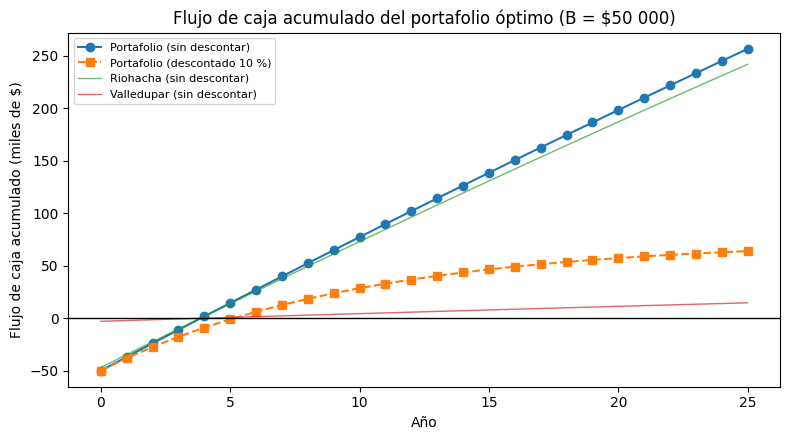


Suma discreta (años 1..25) = $113,857.46
Integral de 0 a 25        = $119,764.58  (error +5.19 %)
Integral de 0.5 a 25.5    = $113,905.21  (error +0.04 %)


In [147]:
# Flujo de caja de una ciudad: año 0 = inversión (negativa), años 1..25 = ingresos con degradación
def flujo_caja(c, paneles, precio):
    t = np.arange(N_ANIOS + 1)
    flujo = E_anual[c] * paneles * precio * (1 - D_DEG) ** t
    flujo[0] = -C_TOTAL[c] * paneles
    return flujo

# VPN de un flujo de caja (descuenta cada año con la tasa r)
def vpn(flujo):
    t = np.arange(len(flujo))
    return np.sum(flujo / (1 + R_DESC) ** t)


# VPN por ciudad y del portafolio
t_anios = np.arange(N_ANIOS + 1)
flujo_total = np.zeros(N_ANIOS + 1)
flujos = {}
filas = []
for c in NOMBRES:
    if x50[c] > 0:
        flujos[c] = flujo_caja(c, x50[c], PRECIO[c])
        flujo_total += flujos[c]
        filas.append({'Ciudad': c, 'Paneles': x50[c],
                      'Inversión ($)': C_TOTAL[c] * x50[c], 'VPN ($)': vpn(flujos[c])})

display(pd.DataFrame(filas).set_index('Ciudad'))
print(f'VPN del portafolio = ${vpn(flujo_total):,.2f}')


# Año de recuperación: primer año con el flujo acumulado >= 0
acumulado = np.cumsum(flujo_total)
acumulado_desc = np.cumsum(flujo_total / (1 + R_DESC) ** t_anios)

def anio_recuperacion(acum):
    for anio, valor in enumerate(acum):
        if valor >= 0:
            return anio
    return None

pb = anio_recuperacion(acumulado)
pb_desc = anio_recuperacion(acumulado_desc)
print('Recuperación sin descontar: año', pb)
print('Recuperación descontada: año', pb_desc)


# Gráfica del flujo de caja acumulado
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t_anios, acumulado / 1000, 'o-', label='Portafolio (sin descontar)')
ax.plot(t_anios, acumulado_desc / 1000, 's--', label='Portafolio (descontado 10 %)')
for c in flujos:
    ax.plot(t_anios, np.cumsum(flujos[c]) / 1000, lw=1, alpha=0.7, label=f'{c} (sin descontar)')
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('Año')
ax.set_ylabel('Flujo de caja acumulado (miles de $)')
ax.set_title('Flujo de caja acumulado del portafolio óptimo (B = $50 000)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# Suma de ingresos vs integral continua
A = sum(E_anual[c] * x50[c] * PRECIO[c] for c in NOMBRES)    # ingreso del primer año sin degradar
q = (1 - D_DEG) / (1 + R_DESC)

suma = A * sum(q ** t for t in range(1, N_ANIOS + 1))
integral = A * (q ** 25 - 1) / math.log(q)                   # integral de 0 a 25
integral_centrada = A * (q ** 25.5 - q ** 0.5) / math.log(q) # integral de 0.5 a 25.5

print(f'\nSuma discreta (años 1..25) = ${suma:,.2f}')
print(f'Integral de 0 a 25        = ${integral:,.2f}  (error {(integral - suma) / suma * 100:+.2f} %)')
print(f'Integral de 0.5 a 25.5    = ${integral_centrada:,.2f}  (error {(integral_centrada - suma) / suma * 100:+.2f} %)')

**Suma vs. integral.** La suma $\sum f(t)$ es una suma de Riemann por la derecha con paso de 1 año. Aproximar con $\int_0^{25}$ sobreestima los ingresos porque integra desde $t=0$, antes del primer pago. Una integral centrada $\int_{0.5}^{25.5}$ se acerca mucho más: la discretización anual importa.

### Conclusiones del Problema 4
El MILP respeta presupuesto, máximo 3 ciudades, mínimo 5 paneles y capacidades. Con B = $50 000 no se abren todas las ciudades por el límite de 3 ciudades y por el presupuesto. La relajación lineal da una cota superior con brecha pequeña, y redondear no garantiza factibilidad ni optimalidad.

# PROBLEMA 5. Análisis de sensibilidad

Se estudia cuánto cambia el VPN con el precio del kWh, desde qué precio entra Leticia en el portafolio y cuánto vale un dólar extra de presupuesto (precio sombra).

## a) Precio del kWh (único para todas las ciudades)

Precio de equilibrio (bisección) = $0.03512/kWh
Precio de equilibrio (fórmula)   = $0.03512/kWh


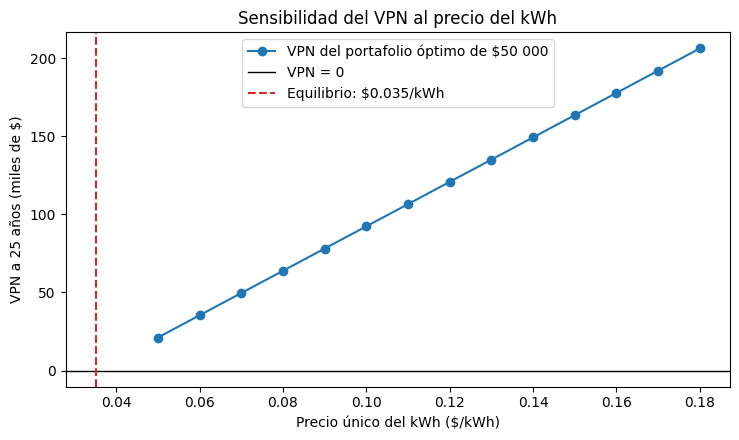

In [148]:
# VPN de un portafolio x (dict ciudad -> paneles) con un precio por ciudad
def vpn_portafolio(x, precios):
    total = 0
    for c in NOMBRES:
        if x[c] > 0:
            total += vpn(flujo_caja(c, x[c], precios[c]))
    return total

# Mismo precio p para todas las ciudades
def precio_unico(p):
    return {c: p for c in NOMBRES}


precios_barrido = np.arange(5, 19) / 100       # 0.05, 0.06, ..., 0.18
vpn_vs_precio = [vpn_portafolio(x50, precio_unico(p)) for p in precios_barrido]


# Bisección para f(x) = 0 en [a, b]
def biseccion(f, a, b, tol=1e-10):
    fa = f(a)
    while b - a > tol:
        m = (a + b) / 2
        fm = f(m)
        if fa * fm <= 0:
            b = m
        else:
            a, fa = m, fm
    return (a + b) / 2

p_eq = biseccion(lambda p: vpn_portafolio(x50, precio_unico(p)), 0.0, 0.5)

# Comprobación con la fórmula cerrada (VPN = 0 -> precio = costo / (FACTOR_VP * energía))
costo_50 = sum(C_TOTAL[c] * x50[c] for c in NOMBRES)
energia_50 = sum(E_anual[c] * x50[c] for c in NOMBRES)
print(f'Precio de equilibrio (bisección) = ${p_eq:.5f}/kWh')
print(f'Precio de equilibrio (fórmula)   = ${costo_50 / (FACTOR_VP * energia_50):.5f}/kWh')


fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(precios_barrido, np.array(vpn_vs_precio) / 1000, 'o-',
        label='VPN del portafolio óptimo de $50 000')
ax.axhline(0, color='k', lw=1, label='VPN = 0')
ax.axvline(p_eq, color='tab:red', ls='--', label=f'Equilibrio: ${p_eq:.3f}/kWh')
ax.set_xlabel('Precio único del kWh ($/kWh)')
ax.set_ylabel('VPN a 25 años (miles de $)')
ax.set_title('Sensibilidad del VPN al precio del kWh')
ax.legend()
plt.tight_layout()
plt.show()

## b) Umbral de Leticia (objetivo: maximizar el VPN)

In [149]:
# Resuelve maximizando VPN con un precio dado para Leticia y los demás fijos
def resolver_con_precio_leticia(p):
    precios = dict(PRECIO)
    precios['Leticia'] = p
    return resolver_portafolio(50_000, objetivo='vpn', precios=precios)


filas = []
for p in np.arange(5, 31) / 100:               # 0.05, 0.06, ..., 0.30
    r = resolver_con_precio_leticia(p)
    fila = {'Precio Leticia ($/kWh)': p, 'VPN ($)': r['obj']}
    fila.update(r['x'])                        # paneles instalados en cada ciudad
    filas.append(fila)

tabla_let = pd.DataFrame(filas).set_index('Precio Leticia ($/kWh)')
display(tabla_let)


# Primer precio de la tabla en el que Leticia entra
entra = tabla_let[tabla_let['Leticia'] > 0]

if len(entra) == 0:
    print('Leticia no entra ni con $0.30/kWh')
elif entra.index[0] <= 0.05:
    print('Leticia ya entra con $0.05/kWh')
else:
    # Se afina entre el precio anterior y ese con bisección
    b = entra.index[0]
    a = b - 0.01
    while b - a > 1e-4:
        m = (a + b) / 2
        if resolver_con_precio_leticia(m)['x']['Leticia'] > 0:
            b = m
        else:
            a = m
    print(f'Leticia entra a partir de ≈ ${b:.4f}/kWh (precio actual: $0.15/kWh)')


# ¿Cambia la asignación de las otras ciudades?
otras = [c for c in NOMBRES if c != 'Leticia']
cambia = len(tabla_let[otras].drop_duplicates()) > 1
print('¿Cambia la asignación en las otras ciudades?', 'SÍ' if cambia else 'NO')

,VPN ($),Riohacha,Valledupar,Medellin,Bogota,Leticia
Precio Leticia ($/kWh),,,,,,
0.05,64253.8,152,0,60,0,0
0.06,64253.8,152,0,60,0,0
0.07,64253.8,152,0,60,0,0
0.08,64253.8,152,0,60,0,0
0.09,64253.8,152,0,60,0,0
0.1,64253.8,152,0,60,0,0
0.11,64253.8,152,0,60,0,0
0.12,64253.8,152,0,60,0,0
0.13,64253.8,152,0,60,0,0


Leticia entra a partir de ≈ $0.1367/kWh (precio actual: $0.15/kWh)
¿Cambia la asignación en las otras ciudades? SÍ


## c) Valor de un dólar extra de presupuesto

In [150]:
res55 = resolver_portafolio(55_000)
dE = res55['obj'] - res50['obj']
print(f"E(B = 50 000) = {res50['obj']:,.2f} kWh/año | E(B = 55 000) = {res55['obj']:,.2f} kWh/año")
print(f'kWh/año adicionales por cada $1 000 extra (MILP): {dE / 5:,.2f}')

# Precio sombra: variable dual de la restricción de presupuesto en la relajación lineal
pi_presupuesto = rel50['prob'].constraints['presupuesto'].pi
print(f'Precio sombra (LP, B = 50 000): {abs(pi_presupuesto):.6f} kWh/año por $ '
      f'-> {abs(pi_presupuesto) * 1000:,.2f} kWh/año por $1 000')

E(B = 50 000) = 163,502.08 kWh/año | E(B = 55 000) = 178,920.94 kWh/año
kWh/año adicionales por cada $1 000 extra (MILP): 3,083.77
Precio sombra (LP, B = 50 000): 3.141881 kWh/año por $ -> 3,141.88 kWh/año por $1 000


**¿Por qué no coinciden?** El precio sombra es la tasa marginal local en la relajación lineal, donde se puede comprar "un poco más" de un panel. En el MILP los paneles son enteros: con $5 000 extra se compra un número entero de paneles y el resto queda sin usar; además puede cambiar la combinación de ciudades abiertas (límite de 3 ciudades, capacidades y mínimos). Por eso el incremento real del MILP es escalonado.

## d) Conclusión: recomendación al comité

In [151]:
abiertas = [c for c in NOMBRES if x50[c] > 0]
paneles_por_ciudad = '; '.join(f'{x50[c]} en {c}' for c in abiertas)

texto = (f'Recomendamos instalar {sum(x50.values())} paneles con una inversión de ${costo_50:,.0f}: '
         f'{paneles_por_ciudad}. La energía esperada es {res50["obj"] / 1000:,.1f} MWh/año y el VPN '
         f'del portafolio a 25 años (r = 10 %, degradación 0.5 %) es de ${vpn(flujo_total):,.0f}, '
         f'con recuperación de la inversión en el año {pb} (sin descontar) y {pb_desc} (descontada). '
         f'El proyecto deja de ser rentable si el precio medio del kWh cae por debajo de ${p_eq:.3f}. '
         f'Los supuestos que podrían cambiar la decisión son: el precio del kWh y su evolución, '
         f'la irradiancia de un año distinto al 2023 (los datos son de un solo año), el modelo simple '
         f'de temperatura y potencia (sin sombras, suciedad ni pérdidas del inversor), la degradación '
         f'real y los costos de instalación y transporte, sobre todo en Leticia.')
print(texto)

Recomendamos instalar 213 paneles con una inversión de $49,990: 200 en Riohacha; 13 en Valledupar. La energía esperada es 163.5 MWh/año y el VPN del portafolio a 25 años (r = 10 %, degradación 0.5 %) es de $63,867, con recuperación de la inversión en el año 4 (sin descontar) y 6 (descontada). El proyecto deja de ser rentable si el precio medio del kWh cae por debajo de $0.035. Los supuestos que podrían cambiar la decisión son: el precio del kWh y su evolución, la irradiancia de un año distinto al 2023 (los datos son de un solo año), el modelo simple de temperatura y potencia (sin sombras, suciedad ni pérdidas del inversor), la degradación real y los costos de instalación y transporte, sobre todo en Leticia.


### Conclusiones del Problema 5
El VPN es lineal en el precio del kWh y el precio de equilibrio marca el riesgo del proyecto. Leticia entra solo si su precio supera cierto umbral. El precio sombra da una cota local del valor de más presupuesto, que en el caso entero se cumple solo de forma aproximada.

---

## Apéndice: ayuda para la defensa

1. **Orden del error:** trapecio $O(h^2)$, Simpson $O(h^4)$; verificado con la pendiente del ajuste log-log (P3-c).
2. **Dorada vs. Newton:** la dorada es lineal (factor 0.618); Newton es cuadrática pero necesita derivadas y un buen punto inicial. Dorada cuando no hay derivadas o se necesita robustez.
3. **Sin $x_i \le M y_i$:** $y_i$ quedaría desconectada de $x_i$; se podrían instalar paneles en ciudades "cerradas", ignorando el límite de 3 ciudades y el mínimo de 5 paneles.
4. **Si el kWh sube a \$0.12/kWh:** con objetivo de energía la asignación no cambia (los precios no entran al objetivo). Con objetivo de VPN sí podría cambiar; se prueba con `resolver_portafolio(50_000, objetivo='vpn', precios=...)`.
5. **Año de recuperación:** es el año en que el flujo acumulado pasa de negativo a positivo; VPN > 0 al final de los 25 años significa que además se recupera el costo del dinero al 10 %.
6. **Parte más sensible a la calidad de los datos:** la energía anual $E_{anual}$ (entra directo al MILP y al VPN) y, por tanto, el manejo de faltantes y el uso de un solo año de irradiancia.